# Simulations of Section VI

This notebook contains the simulations of Section VI of [1]:
1. the setup (plants, variants, budgets, starts, seeds);
2. one run of the four variants, written as a plain loop that follows Algorithm 1 of [1];
3. the check that this loop gives the same numbers as the batched simulator `klpi.simulate` used for the paper's 60960 runs;
4. the driver that runs the whole grid (set `RERUN = True`; about 2 h 10 min on 20 cores, or 8 min with `QUICK = True`);
5. the ratio $r$ of (18) with its bootstrap intervals, and Figs. 1 and 2 compiled from the paper's LaTeX sources.

Without a rerun (`RERUN = False`), step 4 runs nothing, and steps 3 and 5 read the stored per-run results of the paper's runs in `results/`.

[1] A. Bhole, M. Mahmoudi Filabadi, G. Crevecoeur, T. Lefebvre, "KL-Regularized Policy Iteration for Adaptive LQR: Gain Updates and Probing from One Policy Improvement", 2026.

In [1]:
import glob, os, subprocess
from multiprocessing import Pool
import numpy as np
from IPython.display import Image, display
import klpi

RERUN, QUICK = False, False

## 1. Setup

Plants of Table II ($Q=I_n$, $\Sigma_W=I_n$, two inputs), and the settings of the three experiments of Section VI-B.

In [2]:
for name, p in {**klpi.paper_plants(), "EN00 (first of 40 random)": klpi.random_plants()["EN00"]}.items():
    print(f"{name}\nA =\n{p.A}\nB =\n{p.B}\nR = {np.diag(p.R)}\n")

print("alpha =", klpi.ALPHA, " offline samples t0 =", klpi.T0, " online samples T =", klpi.T_RUN)
print("variants:", klpi.VARIANTS)
print("budgets c/C* (standard start):", klpi.FRACTIONS)
print("standard start: P1-P4, the first", klpi.N_SEEDS, "admissible seeds from", klpi.STANDARD_SEED0)
print("poor-gain start: P1-P4, c = C*, the first", klpi.N_SEEDS, "seeds from", klpi.POOR_SEED0,
      "passing", klpi.POOR_RULE)
print("random plants: c = C*/2,", klpi.N_SEEDS_RANDOM_RUN, "seeds run, the first", klpi.N_SEEDS_RANDOM,
      "without a skipped update, blow-up or destabilizing gain analysed")

P1
A =
[[-0.13  0.14 -0.29  0.28]
 [ 0.48  0.09  0.41  0.3 ]
 [-0.01  0.04  0.17  0.43]
 [ 0.14  0.31 -0.29 -0.1 ]]
B =
[[1.63 0.93]
 [0.26 1.79]
 [1.46 1.18]
 [0.77 0.11]]
R = [1. 1.]

P2
A =
[[0.9  0.3 ]
 [0.   0.95]]
B =
[[1. 0.]
 [0. 1.]]
R = [  1. 100.]

P3
A =
[[0.9  0.3 ]
 [0.   0.95]]
B =
[[1.         0.        ]
 [0.         9.92745976]]
R = [1. 1.]

P4
A =
[[0.  0. ]
 [0.  0.9]]
B =
[[2. 0.]
 [0. 1.]]
R = [100.   1.]

EN00 (first of 40 random)
A =
[[-0.92711924 -0.95094075  0.50820252]
 [ 0.34638315  0.03448665  0.00643766]
 [ 0.15583201 -0.09452492 -0.30885001]]
B =
[[ 0.53146219  0.10155431]
 [ 0.53295219  1.48563016]
 [-0.51600628 -1.31557796]]
R = [1. 1.]

alpha = 0.9  offline samples t0 = 100  online samples T = 100000
variants: ('PGAC-iso', 'PGAC-shaped', 'KLPI-iso', 'KLPI')
budgets c/C* (standard start): (0.015625, 0.0625, 0.25, 0.5, 1.0, 2.0)
standard start: P1-P4, the first 480 admissible seeds from 10000
poor-gain start: P1-P4, c = C*, the first 480 seeds from 20000

## 2. One run of the four variants

Every run starts with $t_0=100$ offline samples from $X_0=0$ under inputs $\mathcal N(0,I_2)$ and fits a least-squares estimate of the plant (`klpi.initial_condition`).
The standard start takes the certainty-equivalent gain of this estimate; the poor-gain start takes that of the estimate fitted to the first eight samples.
Then, at every online sample, a variant applies $U_t=K_tX_t+\Omega_t$, updates the recursive least-squares estimate, and takes the gain update of Table I:

| variant | preconditioner $H_{t+1}$ | probing |
|---|---|---|
| KLPI | $\alpha H_t+\hat S_t$ | $\Psi_t=\frac\tau2H_t^{-1}$, $\tau=2c/(m(1-\alpha))$ |
| KLPI-iso | $\alpha H_t+\hat S_t$ | $\sigma_t^2I$ |
| PGAC-iso | $\hat S_t/(1-\alpha)$ | $\sigma_t^2I$ |
| PGAC-shaped | $\hat S_t/(1-\alpha)$ | $\sigma_t^2\hat S_{t-1}^{-1}$ |

with $K_{t+1}=K_t-H_{t+1}^{-1}\hat E_t$, and $\sigma_t^2$ set so that $\mathrm{Tr}(S^\star\Psi_t)$ equals KLPI's at every sample (19).
The function below is one run, written out sample by sample.

In [3]:
def run_one(plant, variant, seed, c, T, start="standard", price=None, alpha=klpi.ALPHA):
    # Returns the per-sample gain-error cost E_t and probing cost P_t (16) of one run.
    # price: KLPI's per-sample probing cost for the same seed, which the other variants match (19).
    sp = klpi.sim_plant(plant)
    m, n = sp.m, sp.n
    precond, shape = klpi.SPEC[variant]                    # ('kl' or 'gn', 'own', 'iso' or 'est')
    tau = klpi.tau_for_budget(c, m, alpha)                 # tau = 2c / (m (1 - alpha))
    x, Phi, Xc, Ah, Bh, K = klpi.initial_condition(sp, seed, start)   # offline phase, K_t0
    Phi, Xc = Phi.copy(), Xc.copy()
    W = np.random.default_rng([seed, 1]).normal(size=(T, n))          # process noise
    XI = np.random.default_rng([seed, 2]).normal(size=(T, m))         # probing: Omega = Psi^(1/2) xi
    S = sp.R + Bh.T @ sp.cost_matrix(K, Ah, Bh) @ Bh       # input Hessian of K_t0 on the estimate
    H = S / (1 - alpha)                                    # H_t0 = S_off / (1 - alpha)
    Ss, Ks = sp.S_star, sp.K_star
    E_cost, P_cost = np.zeros(T), np.zeros(T)
    with np.errstate(all="ignore"):
        for k in range(T):
            # probing covariance Psi_t
            if shape == "own":
                Psi = klpi._sym(0.5 * tau * klpi._inv(H[None]))[0]
            else:
                Lam = np.eye(m) if shape == "iso" else klpi._sym(klpi._inv(S[None]))[0]
                Psi = Lam * (price[k] / np.trace(Ss @ Lam))           # equal probing cost (19)
            P_cost[k] = np.trace(Ss @ Psi)
            d = K - Ks
            E_cost[k] = (d @ x) @ Ss @ (d @ x)                         # gain-error cost (16)
            # apply U_t = K_t X_t + Omega_t and observe X_{t+1}
            u = K @ x + klpi._sqrtm(Psi[None])[0] @ XI[k]
            xn = sp.A @ x + sp.B @ u + sp.LW @ W[k]
            # recursive least squares: [B_hat A_hat] = sum x_next z' (sum z z')^{-1}, z = [u; x]
            z = np.r_[u, x]
            Phi += np.outer(z, z)
            Xc += np.outer(xn, z)
            Th = np.linalg.solve(Phi, Xc.T).T
            Bh, Ah = Th[:, :m], Th[:, m:]
            x = xn
            # input Hessian S_t and slope E_t of K_t on the plant estimate
            P = klpi._kron_lyap((Ah + Bh @ K).T[None], (sp.Q + K.T @ sp.R @ K)[None])
            if not klpi._posdef(P)[0]:
                continue                                    # never happens in the paper's runs
            S = sp.R + Bh.T @ P[0] @ Bh
            E = S @ K + Bh.T @ P[0] @ Ah
            if precond == "kl":
                H = alpha * H + S                           # Algorithm 1: H_{t+1} = alpha H_t + S_t
                K = K - np.linalg.solve(H, E)               # K_{t+1} = K_t - H_{t+1}^{-1} E_t
            else:
                eta = (1 - alpha) / 2                       # PGAC: Gauss-Newton step, same step size
                K = K - 2 * eta * np.linalg.solve(S, E)     # K_{t+1} = K_t - 2 eta S_t^{-1} E_t
    return E_cost, P_cost

## 3. The batched simulator gives the same numbers

The paper's runs use `klpi.simulate`, which advances all variants and seeds of a configuration together, sample by sample, with the arithmetic of `run_one`.
The cell checks this on the first two seeds of P2 at $c=C^\star$ over 2000 samples, and then compares the batched simulator over the full horizon with the stored results of the paper.

In [4]:
p2 = klpi.paper_plants()["P2"]
c = klpi.budget(p2, 1.0)
seeds = klpi.standard_seeds(p2, 2)
batch = klpi.simulate(p2, seeds, c, T=2000)
for j, s in enumerate(seeds):
    E_kl, P_kl = run_one(p2, "KLPI", s, c, 2000)
    for i, v in enumerate(batch["variants"]):
        E, P = (E_kl, P_kl) if v == "KLPI" else run_one(p2, v, s, c, 2000, price=P_kl)
        print(f"seed {s} {v:12s} summed gain-error cost: loop {E.sum():.10g}, "
              f"batched {batch['E_sum'][i, j]:.10g}")

full = klpi.simulate(p2, seeds, c, T=klpi.T_RUN)
stored = klpi.read_setting("standard")[("P2", 1.0)]["E"]
for i, v in enumerate(full["variants"]):
    print(f"{v:12s} T = 1e5: rerun {full['E_sum'][i]}, stored {stored[v][:2]}")

seed 10000 PGAC-iso     summed gain-error cost: loop 324.8375412, batched 324.8375412
seed 10000 PGAC-shaped  summed gain-error cost: loop 251.9817412, batched 251.9817412


seed 10000 KLPI-iso     summed gain-error cost: loop 325.1330866, batched 325.1330866
seed 10000 KLPI         summed gain-error cost: loop 252.7777025, batched 252.7777025


seed 10001 PGAC-iso     summed gain-error cost: loop 147.0852168, batched 147.0852168
seed 10001 PGAC-shaped  summed gain-error cost: loop 112.3579987, batched 112.3579987


seed 10001 KLPI-iso     summed gain-error cost: loop 147.0180297, batched 147.0180297
seed 10001 KLPI         summed gain-error cost: loop 112.3074178, batched 112.3074178


PGAC-iso     T = 1e5: rerun [953.8044176  814.86042571], stored [953.8044176  814.86042571]
PGAC-shaped  T = 1e5: rerun [724.67550413 453.63250301], stored [724.67550413 453.63250301]
KLPI-iso     T = 1e5: rerun [954.11300242 814.74710658], stored [954.11300242 814.74710658]
KLPI         T = 1e5: rerun [725.54167226 453.68529434], stored [725.54167226 453.68529434]


## 4. Running the grid

Each configuration (setting, plant, budget) is simulated for its seeds in chunks of ten, in parallel, and its per-run results are written to `results/runs_<setting>.csv` (summed gain-error cost of every variant per seed), with the running sums of Fig. 1(c) in `windows_standard.npz` and the relative gaps of Fig. 2(b) in `gaps_poor.npz`.

In [5]:
def run_chunk(args):
    setting, plant, f, seeds, variants, start, T = args
    chk = klpi.dense_checkpoints(T) if setting == "poor" else None   # Fig. 2(b) needs every early sample
    return klpi.simulate(plant, seeds, klpi.budget(plant, f), variants, start=start, T=T,
                         alpha=klpi.ALPHA, chk=chk)

def run_grid(setting, n_seeds=None, T=klpi.T_RUN, out=klpi.RESULTS):
    cells = klpi.cells(setting, n_seeds=n_seeds, T=T)           # plants, budgets, seed rules
    tasks = [(i, (setting, cl.plant, cl.f, cl.seeds[j:j + 10], cl.variants, cl.start, T))
             for i, cl in enumerate(cells) for j in range(0, len(cl.seeds), 10)]
    with Pool() as pool:
        res = pool.map(run_chunk, [t for _, t in tasks])
    results = []
    for i, cl in enumerate(cells):
        parts = [r for (ci, _), r in zip(tasks, res) if ci == i]
        d = {k: np.concatenate([r[k] for r in parts], axis=1)
             for k in ("E_sum", "P_sum", "status", "skips", "unstable", "E_cum", "delta")}
        d.update(plant=cl.plant.name, f=cl.f, seeds=cl.seeds, variants=list(cl.variants),
                 k=parts[0]["k"], T=T)
        results.append(d)
    klpi.write_setting(setting, results, out)

out = os.path.join(klpi.RESULTS, "quick") if QUICK else klpi.RESULTS
if RERUN:
    for setting in ("standard", "poor", "random"):
        run_grid(setting, n_seeds=(6 if setting == "random" else 24) if QUICK else None, out=out)

## 5. The ratio $r$ and the figures

For two variants a and b, $r=\sum_s\sum_t\mathcal E^{\mathrm a}_{t,s}/\sum_s\sum_t\mathcal E^{\mathrm b}_{t,s}$ (18), with a 95% paired-bootstrap interval over the seeds (`klpi.ratio`: 5000 resamples of the seeds); Fig. 1(c) uses the same ratio over windows of online samples (`klpi.windowed_ratio`).
`klpi.write_tables` computes these from the per-run results and writes the tables that the figure sources read.

In [6]:
klpi.write_tables(out)

def show(name):
    tex = glob.glob("/usr/local/texlive/*/bin/*")
    env = dict(os.environ, PATH=":".join(tex[:1] + [os.environ["PATH"]]))
    data = os.path.relpath(os.path.join(out, "tables"), "figures")
    src = open(f"figures/{name}.tex").read().replace("{../results/tables}", "{" + data + "}")
    open(f"figures/_{name}.tex", "w").write(src)
    subprocess.run(["pdflatex", "-interaction=nonstopmode", "-halt-on-error", f"_{name}.tex"],
                   cwd="figures", env=env, check=True, capture_output=True)
    subprocess.run(["pdftoppm", "-png", "-r", "200", "-singlefile", f"_{name}.pdf", name],
                   cwd="figures", check=True)
    for ext in ("tex", "aux", "log", "pdf"):
        os.remove(f"figures/_{name}.{ext}")
    display(Image(f"figures/{name}.png"))

**Fig. 1.** Ratio $r$ of KLPI to PGAC-iso from the standard start, with $95\%$ bootstrap intervals over the seeds ($480$ per plant for P1–P4, $50$ per random plant): (a) whole runs on P1–P4; (b) whole runs on the random plants, $c=C^\star/2$; (c) windowed ratio on P1–P4, $c=C^\star$.

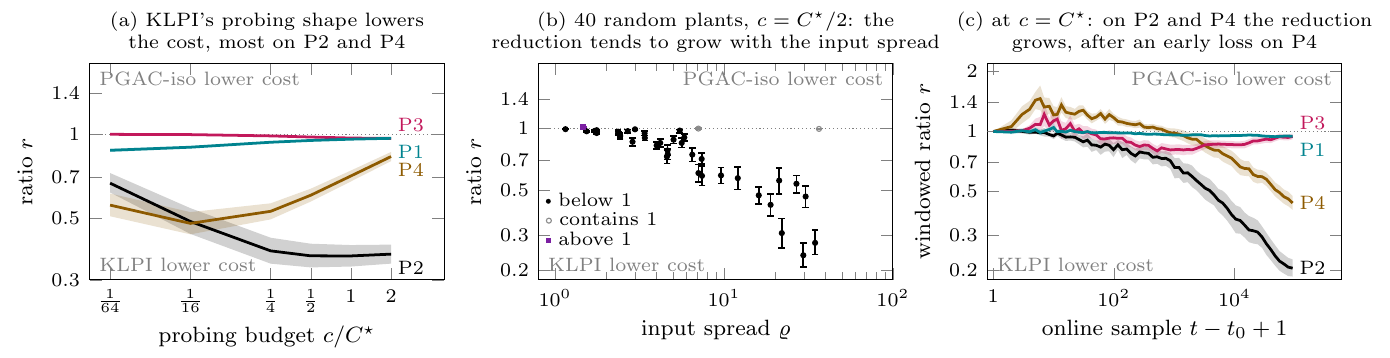

In [7]:
show("fig1")

**Fig. 2.** Effect of the averaging from the poor-gain start at $c=C^\star$ ($480$ seeds per plant): (a) the ratio $r$ within each pair that differs only in the averaging, with $95\%$ bootstrap intervals; (b) the ratio of the median relative gap of KLPI-iso to that of PGAC-iso, averaged over short windows of online samples.

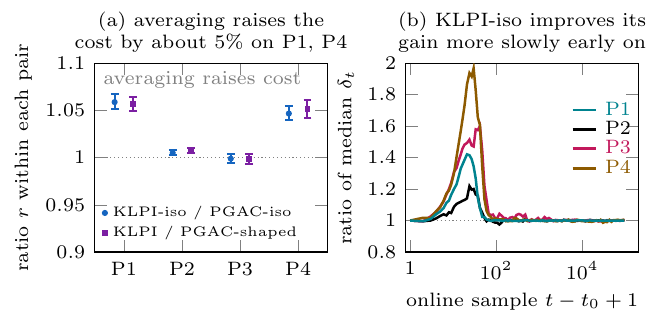

In [8]:
show("fig2")